# Prompt Guard: Milestone 2A, tuning TF-IDF + Logistic Regression

**Starting point.** Our baseline (`baseline_tfidf_logreg.ipynb`, `C = 10`) blocks **91.8 %** of all
block texts on validation. Our target is **at least 95 %**, while at most **5 %** of harmless prompts
may be blocked by mistake.

**Goal of this notebook.** Find out how close we get to the target *without* changing the model type.
We only turn two "levers" and measure the effect of each one separately:

| Lever | What it is | Why it could help |
|---|---|---|
| **1. `C`** | How closely the model may follow the training data | `C = 10` was the largest value we tried *and* the best one, so maybe the optimum is even higher (`30`, `100`) |
| **2. Block threshold** | From which probability a prompt is blocked (default: the class with the highest probability wins) | A lower threshold blocks *more* prompts: more security, but also more false alarms. We search for the best trade-off |

**What we deliberately do NOT change** (so the comparison with the baseline stays fair):
- the same split (`data/splits.csv`, fingerprint is logged),
- the same policy (`config/policy.yaml`, version is logged),
- the same TF-IDF settings as the baseline (character pieces of 2 to 5 characters).

**Rules we follow**
- We train only on **train** and choose all settings on **validation**.
- The **test set is not touched** in this notebook. It is used once at the very end of the project (Milestone 5).
- Every tried setting becomes **its own run in MLflow**, so the whole team can compare it.

**Structure**
1. Setup · 2. Load the data · 3. Turn the texts into numbers · 4. Our evaluation function ·
5. Lever 1: `C` · 6. Lever 2: block threshold · 7. Choose the operating point · 8. Per language ·
9. What is still missed? · 10. Own prompts · 11. Response time · 12. Save and log the final model · 13. Conclusion

## 1. Setup

Same imports and settings as in the baseline notebook. New are only `yaml` (to read the policy version
directly from `config/policy.yaml` instead of typing it by hand) and `mlflow`.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import joblib
import mlflow

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

# Our shared helper file src/data_utils.py (same split + same labels for every model)
sys.path.append("../src")
from data_utils import load_all_splits, split_fingerprint, load_policy

# --- Settings ----------------------------------------------------------------------
SEED = 42                                   # same seed as the split -> reproducible
CLASSES = ["allow", "warn", "block"]        # fixed order for all tables and charts
PROJECT_DIR = Path("..").resolve()          # the project folder (one level above notebooks/)
MODEL_DIR = PROJECT_DIR / "models"

# Our project targets (from the pitch). We write them down once, so every table can compare against them.
TARGET_RECALL_BLOCK = 0.95       # at least 95 % of block texts must be blocked
TARGET_FALSE_BLOCK = 0.05        # at most 5 % of harmless (allow) texts may be blocked

# Read the policy version from the YAML file instead of typing "0.1" by hand.
# If someone changes the policy later, the MLflow runs automatically show the new version.
with open(PROJECT_DIR / "config" / "policy.yaml", encoding="utf-8") as f:
    POLICY_VERSION = str(yaml.safe_load(f)["version"])

# --- Chart style (same as in the other notebooks) ------------------------------------
BLUE = "#2a78d6"
ORANGE = "#eb6834"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Policy version:", POLICY_VERSION)
print("Setup done.")

c:\Users\olga9\Desktop\Studium Heilbronn\Kurse\WiSe26\AIO - AI Operations\AIOps_PromptGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Policy version: 0.1
Setup done.


### Where do the MLflow runs go?

- If the environment variable `MLFLOW_TRACKING_URI` is set (for example in a `.env` file for our
  **shared team server**), the runs go there. Anni sets up the shared server; until then nothing has to be done.
- Otherwise the runs are stored **locally** in `mlflow.db` / `mlruns/` in the project folder, exactly like in the
  baseline notebook. Then you can look at them with `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

**Never** write a password or token directly into the notebook: the notebook is pushed to GitHub, the `.env` file is not.

In [2]:
# python-dotenv reads the file .env (if it exists) and puts its values into the environment variables.
# If the package is not installed, we simply skip this step.
try:
    from dotenv import load_dotenv
    load_dotenv(PROJECT_DIR / ".env")
except ImportError:
    pass

if os.getenv("MLFLOW_TRACKING_URI"):
    # Shared server: MLflow reads the address (and user name / token) from the environment by itself
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard")
else:
    # Local fallback: same place as the baseline notebook
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}")
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard", artifact_location=(PROJECT_DIR / "mlruns").as_uri())
mlflow.set_experiment("promptguard")

print("MLflow tracking URI:", mlflow.get_tracking_uri())

MLflow tracking URI: sqlite:///C:/Users/olga9/Desktop/Studium Heilbronn/Kurse/WiSe26/AIO - AI Operations/AIOps_PromptGuard/mlflow.db


## 2. Load the data

Exactly as in the baseline. We deliberately do **not** create a variable for the test set.

In [3]:
splits = load_all_splits()
train = splits["train"]
val = splits["validation"]
del splits        # removes the test set from memory, so we cannot use it by accident

SPLIT_FINGERPRINT = split_fingerprint()
print("Split fingerprint:", SPLIT_FINGERPRINT, "(baseline: 6afd6a257de1)")

X_train, y_train = train["source_text"], train["decision"]
X_val, y_val = val["source_text"], val["decision"]
print(f"train: {len(train):,} texts | validation: {len(val):,} texts")

Split fingerprint: 6afd6a257de1 (baseline: 6afd6a257de1)
train: 146,455 texts | validation: 31,380 texts


## 3. Turn the texts into numbers (same TF-IDF as the baseline)

We use **exactly the same** vectorizer settings as the baseline. If we changed them too, we would not know
whether a better result comes from the new `C` / threshold or from the new vectorizer.

The vectorizer is fitted **only on train** (no data leakage). This step takes a few minutes.

In [4]:
TFIDF_PARAMS = dict(
    analyzer="char_wb",       # character pieces inside words
    ngram_range=(2, 5),       # pieces of 2 to 5 characters
    min_df=5,                 # ignore pieces that occur in fewer than 5 texts
    max_features=300_000,     # keep at most 300,000 pieces
    sublinear_tf=True,        # 10x the same piece counts more, but not 10x as much
    dtype=np.float32,         # half the memory
)
vectorizer = TfidfVectorizer(**TFIDF_PARAMS)

start = time.perf_counter()
X_train_vec = vectorizer.fit_transform(X_train)   # learn the pieces on train AND convert train
X_val_vec = vectorizer.transform(X_val)           # only convert validation
print(f"Vectorising took {time.perf_counter() - start:.0f} s, matrix: {X_train_vec.shape}")

Vectorising took 155 s, matrix: (146455, 300000)


## 4. Our evaluation function

To compare all settings fairly, **every** setting is measured with the **same function**.
Besides the metrics from the baseline, we add two numbers that match our project targets directly:

| Metric | Question it answers | Target |
|---|---|---|
| `recall_block` | Of all texts that *should* be blocked, how many are blocked? | ≥ 0.95 |
| `false_block_allow` | Of all **harmless** (allow) texts, how many are wrongly blocked? | ≤ 0.05 |
| `false_block_warn` | Of all **warn** texts, how many are blocked instead of only warned? | as low as possible |
| `macro_f1` | Overall quality, every class counts the same | as high as possible |

`false_block_allow` is the number for our stakeholder: every false block is an employee who cannot work and
might stop using the tool.

In [5]:
def evaluate(y_true, y_pred) -> dict:
    # Returns all metrics we compare, as one dictionary (one row in a table / one MLflow run).
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    is_allow = y_true == "allow"
    is_warn = y_true == "warn"
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "recall_block": recall_score(y_true, y_pred, labels=["block"], average="macro"),
        "recall_warn": recall_score(y_true, y_pred, labels=["warn"], average="macro"),
        "recall_allow": recall_score(y_true, y_pred, labels=["allow"], average="macro"),
        # share of true allow texts that the model blocks (our "false alarm" number)
        "false_block_allow": float((y_pred[is_allow] == "block").mean()),
        # share of true warn texts that the model blocks (annoying, but less bad than blocking harmless text)
        "false_block_warn": float((y_pred[is_warn] == "block").mean()),
    }


def meets_targets(metrics: dict) -> bool:
    # True if BOTH project targets are reached
    return metrics["recall_block"] >= TARGET_RECALL_BLOCK and metrics["false_block_allow"] <= TARGET_FALSE_BLOCK

## 5. Lever 1: try higher values for `C`

**Reminder:** `C` controls how closely the model may follow the training data.
Small `C` = simple model (may learn too little), large `C` = the model follows the training texts very closely
(may learn them by heart). In the baseline, `C = 10` was the largest tried value and the best one.
When the best value is at the *edge* of the tried range, the optimum may lie beyond it. So we try `30` and `100`
and train `10` again as the reference in the same run of this notebook.

Notes:
- Larger `C` needs more training steps. We allow `max_iter=3000` and record whether the model **converged**
  (finished learning) or stopped because it hit the step limit.
- Each `C` is logged as **its own MLflow run** (`tfidf_logreg_C10`, `..._C30`, ...).
- Runtime: in the baseline run each `C` took about 3.5 to 4 minutes (C=1: 203 s, C=3: 252 s, C=10: 235 s).
  Larger `C` usually needs more steps, so plan about **20 to 30 minutes** for this whole cell. Run it once and take a coffee.

In [6]:
C_VALUES = [10.0, 30.0, 100.0]
MAX_ITER = 3000

c_results = []   # one row per C
models = {}      # keep every trained model, we need the best one later

for C in C_VALUES:
    model = LogisticRegression(C=C, class_weight="balanced", max_iter=MAX_ITER, random_state=SEED)

    # Catch the warning "did not converge" and turn it into a yes/no column instead of red text
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.perf_counter()
        model.fit(X_train_vec, y_train)
        train_seconds = time.perf_counter() - start
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)

    metrics = evaluate(y_val, model.predict(X_val_vec))   # default rule: highest probability wins
    models[C] = model
    c_results.append({"C": C, **metrics, "converged": converged, "training time (s)": round(train_seconds)})

    # One MLflow run per C value
    with mlflow.start_run(run_name=f"tfidf_logreg_C{int(C)}"):
        mlflow.set_tag("milestone", "M2")
        mlflow.set_tag("experiment_part", "A_tune_C")
        mlflow.log_params({
            "model": "tfidf_logreg", "analyzer": "char_wb", "ngram_range": "2-5",
            "min_df": 5, "max_features": 300_000, "C": C, "class_weight": "balanced",
            "max_iter": MAX_ITER, "block_threshold": "argmax",
            "split_fingerprint": SPLIT_FINGERPRINT, "policy_version": POLICY_VERSION,
        })
        mlflow.log_metrics({f"val_{k}": v for k, v in metrics.items()})
        mlflow.log_metric("converged", int(converged))

    print(f"C={C:>5}: recall block {metrics['recall_block']:.3f}, macro F1 {metrics['macro_f1']:.3f}, "
          f"converged={converged}, {train_seconds:.0f} s")

c_results = pd.DataFrame(c_results).set_index("C").round(4)
display(c_results)

C= 10.0: recall block 0.919, macro F1 0.870, converged=True, 268 s
C= 30.0: recall block 0.917, macro F1 0.877, converged=True, 326 s
C=100.0: recall block 0.915, macro F1 0.875, converged=True, 284 s


,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,converged,training time (s)
C,,,,,,,,
10.0,0.8704,0.9189,0.9102,0.8746,0.0098,0.0401,True,268
30.0,0.8769,0.9171,0.9221,0.8543,0.0114,0.0365,True,326
100.0,0.8754,0.9149,0.9252,0.8185,0.0138,0.0403,True,284


**How to choose.** We take the `C` with the best **macro F1**. If two values are almost equal
(difference below 0.002), we take the **smaller** one: a simpler model usually works better on new texts.

In [7]:
best_f1 = c_results["macro_f1"].max()
# all C values that are at most 0.002 below the best F1, then the smallest of them
BEST_C = c_results.index[c_results["macro_f1"] >= best_f1 - 0.002].min()
best_model = models[BEST_C]
pipeline = Pipeline([("tfidf", vectorizer), ("logreg", best_model)])
print("Chosen C:", BEST_C)

Chosen C: 30.0


## 6. Lever 2: the block threshold

**The idea in one example.** For every prompt the model gives three probabilities, for example

| allow | warn | block |
|---|---|---|
| 0.20 | **0.45** | 0.35 |

With the default rule ("highest probability wins") this prompt is **warn**, even though the model thinks
there is a 35 % chance that it contains a password or an IBAN.

For our stakeholder, a missed block is much more expensive than an unnecessary one. So we change the rule:

> **If the block probability is at least `t`, the prompt is blocked.**
> Otherwise the higher one of allow and warn wins.

With `t = 0.30` the example above becomes **block**. The lower `t`, the more prompts are blocked:
recall block goes **up**, but the number of false alarms goes **up** too. We try many values of `t`
and look at both numbers side by side.

**Important:** we choose `t` on **validation**, never on the test set.

In [8]:
def predict_with_threshold(proba: np.ndarray, classes, threshold: float) -> np.ndarray:
    # proba: the output of predict_proba, one row per prompt, one column per class
    # classes: the column order of proba (model.classes_)
    classes = list(classes)
    p_block = proba[:, classes.index("block")]

    # Best class among the NON-block classes (allow or warn)
    other = [c for c in classes if c != "block"]
    other_idx = [classes.index(c) for c in other]
    best_other = np.array(other)[proba[:, other_idx].argmax(axis=1)]

    # Block if p_block >= threshold, otherwise the better of allow / warn
    return np.where(p_block >= threshold, "block", best_other)


# Probabilities only have to be calculated once; trying many thresholds is then very fast
val_proba = best_model.predict_proba(X_val_vec)
model_classes = best_model.classes_

# Sanity check: with the new rule, "argmax" behaves like threshold ~0.5 but not exactly.
# So we also keep the default rule as the first row for comparison.
rows = [{"threshold": "argmax (default)", **evaluate(y_val, best_model.predict(X_val_vec))}]
for t in [0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10, 0.05]:
    rows.append({"threshold": t, **evaluate(y_val, predict_with_threshold(val_proba, model_classes, t))})

sweep = pd.DataFrame(rows)
sweep["meets both targets"] = sweep.apply(meets_targets, axis=1)
display(sweep.round(4))

,threshold,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,meets both targets
0,argmax (default),0.8769,0.9171,0.9221,0.8543,0.0114,0.0365,False
1,0.5,0.8767,0.9150,0.9229,0.8555,0.0090,0.0355,False
2,0.45,0.8763,0.9232,0.9178,0.8543,0.0114,0.0407,False
3,0.4,0.8748,0.9291,0.9114,0.8531,0.0134,0.0472,False
4,0.35,0.8728,0.9357,0.9033,0.8523,0.0159,0.0554,False
5,0.3,0.8709,0.9426,0.8958,0.8506,0.0179,0.0630,False
6,0.25,0.8679,0.9481,0.8862,0.8498,0.0199,0.0728,False
7,0.2,0.8639,0.9549,0.8737,0.8486,0.0216,0.0856,True
8,0.15,0.8572,0.9605,0.8568,0.8457,0.0277,0.1028,True
9,0.1,0.8463,0.9685,0.8311,0.8364,0.0383,0.1295,True


**The trade-off as a chart.** The blue line should be *above* the dashed 95 % line, the orange line *below*
the dashed 5 % line. Where both are true, the target is reached.

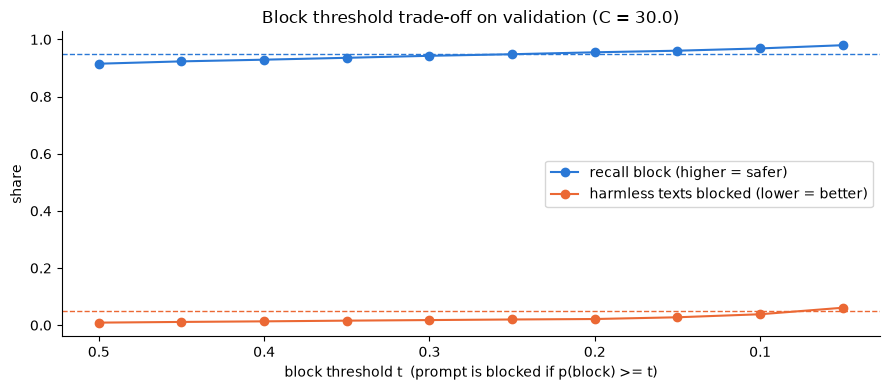

In [9]:
curve = sweep[sweep["threshold"] != "argmax (default)"].astype({"threshold": float})

fig, ax = plt.subplots()
ax.plot(curve["threshold"], curve["recall_block"], marker="o", color=BLUE, label="recall block (higher = safer)")
ax.plot(curve["threshold"], curve["false_block_allow"], marker="o", color=ORANGE,
        label="harmless texts blocked (lower = better)")
ax.axhline(TARGET_RECALL_BLOCK, color=BLUE, linestyle="--", linewidth=1)
ax.axhline(TARGET_FALSE_BLOCK, color=ORANGE, linestyle="--", linewidth=1)
ax.set_xlabel("block threshold t  (prompt is blocked if p(block) >= t)")
ax.set_ylabel("share")
ax.invert_xaxis()                     # left = strict default, right = blocks more
ax.set_title(f"Block threshold trade-off on validation (C = {BEST_C})")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

## 7. Choose the operating point

We write the decision rule down **before** we look at the numbers, so the choice is easy to argue:

1. If there are thresholds that reach **both** targets, take the **highest** of them
   (= the fewest false alarms while still safe enough).
2. If no threshold reaches both targets, take the threshold with the **highest recall block** among those that
   keep false alarms **≤ 5 %**. Then we know honestly: *"With this model the maximum is X %"*, which is the argument
   for the context-reading models of Milestone 2B / 2C.

In [10]:
both = curve[curve["meets both targets"]]
if len(both) > 0:
    BLOCK_THRESHOLD = float(both["threshold"].max())
    reason = "highest threshold that reaches both targets"
else:
    safe = curve[curve["false_block_allow"] <= TARGET_FALSE_BLOCK]
    if len(safe) > 0:
        BLOCK_THRESHOLD = float(safe.loc[safe["recall_block"].idxmax(), "threshold"])
        reason = "both targets not reachable; best recall block with <= 5 % false alarms"
    else:
        BLOCK_THRESHOLD = 0.5
        reason = "even the strictest threshold has > 5 % false alarms; keep 0.5"

y_val_pred = predict_with_threshold(val_proba, model_classes, BLOCK_THRESHOLD)
final_metrics = evaluate(y_val, y_val_pred)

print(f"Chosen threshold: {BLOCK_THRESHOLD}  ({reason})")
for name, value in final_metrics.items():
    print(f"  {name:<18} {value:.4f}")
print()
print(classification_report(y_val, y_val_pred, labels=CLASSES, digits=3))

Chosen threshold: 0.2  (highest threshold that reaches both targets)
  macro_f1           0.8639
  recall_block       0.9549
  recall_warn        0.8737
  recall_allow       0.8486
  false_block_allow  0.0216
  false_block_warn   0.0856

              precision    recall  f1-score   support

       allow      0.720     0.849     0.779      2457
        warn      0.958     0.874     0.914     19055
       block      0.848     0.955     0.898      9868

    accuracy                          0.897     31380
   macro avg      0.842     0.892     0.864     31380
weighted avg      0.905     0.897     0.899     31380



In [11]:
# Confusion matrix of the chosen operating point (rows = true class, columns = predicted class)
cm = confusion_matrix(y_val, y_val_pred, labels=CLASSES)
display(pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]))

,pred allow,pred warn,pred block
true allow,2085,319,53
true warn,775,16648,1632
true block,34,411,9423


## 8. Results per language

German matters most for our company. We check whether the chosen setting works equally well in every language.

In [12]:
rows = []
for language, part in val.assign(pred=y_val_pred).groupby("language"):
    rows.append({"language": language, "texts": len(part), **evaluate(part["decision"], part["pred"])})
per_language = pd.DataFrame(rows).set_index("language").round(4)
display(per_language)

,texts,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn
language,,,,,,,
de,7922,0.8670,0.9535,0.8751,0.8585,0.0228,0.0856
en,6522,0.8487,0.9520,0.8618,0.8214,0.0207,0.0911
fr,9292,0.8733,0.9541,0.8851,0.8507,0.0169,0.0803
it,7644,0.8629,0.9598,0.8685,0.8600,0.0267,0.0874


## 9. What is still missed?

Which block labels are in the block texts that the model **still** lets through? This tells us which kinds of
sensitive data need a model that reads the context (Milestone 2C, NER).

In [13]:
policy = load_policy()
missed = val.assign(pred=y_val_pred)
missed = missed[(missed["decision"] == "block") & (missed["pred"] != "block")]
print(f"Missed block texts: {len(missed):,} of {(y_val == 'block').sum():,}")

block_labels = [
    entry["label"]
    for mask in missed["privacy_mask"]
    for entry in mask
    if policy["label_to_decision"].get(entry["label"]) == "block"
]
display(pd.Series(block_labels, dtype="object").value_counts().to_frame("count in missed texts"))

Missed block texts: 445 of 9,868


,count in missed texts
PASSWORD,202
SSN,106
ACCOUNTNUMBER,66
PIN,39
CREDITCARDCVV,30
IBAN,2
CREDITCARDNUMBER,2
MASKEDNUMBER,1


## 10. Our own prompts (realistic check)

The dataset is synthetic and contains **no prompt without PII**, so the numbers above say little about
harmless everyday prompts. That is why we write our own test prompts in `data/own_prompts.csv`
(columns `prompt`, `expected_decision`, `language`, `category`).

**Rule:** we only **look** at this file, we never choose `C` or the threshold because of it.
Otherwise it would no longer be an honest check. If the file does not exist yet, a few example prompts are used.

In [14]:
own_path = PROJECT_DIR / "data" / "own_prompts.csv"
if own_path.exists():
    own = pd.read_csv(own_path)
else:
    print("data/own_prompts.csv not found, using 5 example prompts.")
    own = pd.DataFrame({
        "prompt": [
            "Fasse bitte diesen Text über unsere neue Urlaubsregelung zusammen.",
            "Schreibe eine E-Mail an anna.schmidt@firma.de wegen des Termins am Montag.",
            "Bitte überweise 500 EUR auf DE89 3704 0044 0532 0130 00.",
            "Mein Passwort für das Portal ist Sommer2024! Kannst du prüfen, ob es sicher ist?",
            "Erstelle eine Tabelle mit den Umsätzen 2023 für die Regionen Nord und Süd.",
        ],
        "expected_decision": ["allow", "warn", "block", "block", "allow"],
        "language": ["de"] * 5,
        "category": ["harmless", "email", "iban", "password", "harmless numbers"],
    })

own_proba = pipeline.predict_proba(own["prompt"].tolist())
own["p_block"] = own_proba[:, list(model_classes).index("block")].round(3)
own["default rule"] = pipeline.predict(own["prompt"].tolist())
own["with threshold"] = predict_with_threshold(own_proba, model_classes, BLOCK_THRESHOLD)
own["correct"] = own["with threshold"] == own["expected_decision"]

OWN_METRICS = evaluate(own["expected_decision"], own["with threshold"])
print(f"Own prompts: {len(own)} | correct: {own['correct'].mean():.1%} | "
      f"recall block: {OWN_METRICS['recall_block']:.3f} | harmless blocked: {OWN_METRICS['false_block_allow']:.3f}")
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 300):
    display(own[["prompt", "expected_decision", "default rule", "with threshold", "p_block", "correct"]])

Own prompts: 200 | correct: 65.0% | recall block: 0.933 | harmless blocked: 0.150


,prompt,expected_decision,default rule,with threshold,p_block,correct
0,Fasse bitte diesen Text über unsere neue Urlaubsregelung zusammen.,allow,allow,allow,0.000,True
1,Erstelle eine Tabelle mit den Umsätzen 2023 für die Regionen Nord und Süd.,allow,warn,block,0.362,False
2,Schreib mir eine kurze Agenda für das Teammeeting am Donnerstag um 10 Uhr.,allow,allow,allow,0.001,True
3,wie sag ich nem lieferanten höflich ab?,allow,allow,allow,0.000,True
4,"Übersetze ins Englische: Unser Ziel ist es, die Lieferzeiten um 15 % zu senken.",allow,warn,warn,0.001,False
5,Gib mir 5 Ideen für einen LinkedIn-Post zu unserem Firmenjubiläum.,allow,warn,warn,0.014,False
6,Erkläre den Unterschied zwischen Brutto und Netto bei einer Rechnung über 1.250 EUR.,allow,warn,warn,0.003,False
7,Wie erstelle ich ein sicheres Passwort? Ich brauche Tipps für eine Schulung.,allow,block,block,0.686,False
8,Schreib eine Mail ans Team: Das Büro in Stuttgart bleibt am 24.12. geschlossen.,allow,warn,warn,0.001,False
9,Formuliere eine Stellenanzeige für eine Werkstudentin im Controlling.,allow,warn,warn,0.000,False


## 11. Response time

The threshold rule only adds one comparison, so the speed should stay at ~2 ms. We measure it anyway, with the
same method as the baseline: 1,000 single prompts, median and 95th percentile.

In [15]:
sample = X_val.sample(1000, random_state=SEED).tolist()
times_ms = []
for prompt in sample:
    start = time.perf_counter()
    predict_with_threshold(pipeline.predict_proba([prompt]), model_classes, BLOCK_THRESHOLD)
    times_ms.append((time.perf_counter() - start) * 1000)

LATENCY_MEDIAN_MS = float(np.median(times_ms))
LATENCY_P95_MS = float(np.percentile(times_ms, 95))
print(f"Median: {LATENCY_MEDIAN_MS:.2f} ms | 95th percentile: {LATENCY_P95_MS:.2f} ms (target: < 100 ms)")

Median: 3.19 ms | 95th percentile: 5.57 ms (target: < 100 ms)


## 12. Save and log the final model

The threshold is part of the model: without it, the API would make different decisions than this notebook.
So we save **pipeline and threshold together** in one file (`models/tfidf_logreg_tuned.joblib`).

Later in FastAPI:
```python
bundle = joblib.load("models/tfidf_logreg_tuned.joblib")
proba = bundle["pipeline"].predict_proba([prompt])
# then: block if proba of "block" >= bundle["block_threshold"]
```

In MLflow this becomes the run `tfidf_logreg_tuned` with the tag `candidate = true`, plus the full threshold
table as a CSV file, so the trade-off can be checked later without running the notebook again.

In [16]:
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "tfidf_logreg_tuned.joblib"
bundle = {
    "pipeline": pipeline,
    "block_threshold": BLOCK_THRESHOLD,
    "classes": list(model_classes),
    "split_fingerprint": SPLIT_FINGERPRINT,
    "policy_version": POLICY_VERSION,
}
joblib.dump(bundle, model_path)
print(f"Saved to {model_path} ({model_path.stat().st_size / 1e6:.0f} MB)")

sweep_path = PROJECT_DIR / "reports" / "tfidf_threshold_sweep.csv"
sweep_path.parent.mkdir(exist_ok=True)
sweep.round(4).to_csv(sweep_path, index=False)

with mlflow.start_run(run_name="tfidf_logreg_tuned"):
    mlflow.set_tag("milestone", "M2")
    mlflow.set_tag("experiment_part", "A_threshold")
    mlflow.set_tag("candidate", "true")
    mlflow.log_params({
        "model": "tfidf_logreg", "analyzer": "char_wb", "ngram_range": "2-5",
        "min_df": 5, "max_features": 300_000, "C": BEST_C, "class_weight": "balanced",
        "max_iter": MAX_ITER, "block_threshold": BLOCK_THRESHOLD, "threshold_reason": reason,
        "split_fingerprint": SPLIT_FINGERPRINT, "policy_version": POLICY_VERSION,
    })
    # Same metric names as the baseline run, so both appear side by side in the MLflow UI
    mlflow.log_metrics({f"val_{k}": v for k, v in final_metrics.items()})
    mlflow.log_metrics({
        "val_de_macro_f1": per_language.loc["de", "macro_f1"],
        "val_de_recall_block": per_language.loc["de", "recall_block"],
        "val_de_false_block_allow": per_language.loc["de", "false_block_allow"],
        "own_prompts_accuracy": float(own["correct"].mean()),
        "own_prompts_false_block_allow": OWN_METRICS["false_block_allow"],
        "latency_median_ms": LATENCY_MEDIAN_MS,
        "latency_p95_ms": LATENCY_P95_MS,
    })
    mlflow.log_artifact(str(model_path))
    mlflow.log_artifact(str(sweep_path))

print("Run logged to MLflow.")

Saved to C:\Users\olga9\Desktop\Studium Heilbronn\Kurse\WiSe26\AIO - AI Operations\AIOps_PromptGuard\models\tfidf_logreg_tuned.joblib (13 MB)
Run logged to MLflow.


## 13. Conclusion

Split fingerprint `6afd6a257de1`, policy version 0.1, validation set (31,380 texts). Chosen: **C = 30, block threshold 0.2**.

| | Baseline (`C = 10`, default rule) | Tuned (`C = 30`, threshold `0.2`) | Target |
|---|---|---|---|
| Recall block | 0.918 (811 of 9,868 missed) | **0.955** (445 missed) | ≥ 0.95 ✔ |
| Harmless (allow) texts blocked (`false_block_allow`) | 0.010 | 0.022 | ≤ 0.05 ✔ |
| Warn texts blocked instead of warned (`false_block_warn`) | 0.040 | 0.086 | as low as possible |
| Macro F1 | 0.870 | 0.864 | |
| Recall block German | 0.912 | 0.954 | ≥ 0.90 ✔ |
| Own 200 German prompts correct | not measured | 130 of 200 (65 %) | |
| Response time p95 | 1.3 ms (other laptop) | 5.8 ms | < 100 ms ✔ |

**What the levers did**
- **Higher `C`** did not help recall block: 0.919 / 0.917 / 0.915 for `C` = 10 / 30 / 100 (all models converged).
  `C = 30` was chosen because of the best macro F1 (0.877 vs. 0.870). The difference is small.
- **The block threshold** is the lever that matters: lowering it from "highest probability wins" to 0.2 raised
  recall block from 0.917 to 0.955, so about 370 more block texts are caught. The price: harmless texts blocked
  rose from 1.1 % to 2.2 %, and warn texts blocked instead of warned from 3.7 % to 8.6 % (about 900 more texts).
  Blocking a warn text is annoying but safe, so we accept this trade-off.

**Answer to our question:** Yes, on the validation set TF-IDF + Logistic Regression reaches both targets:
95.5 % block recall with 2.2 % harmless texts blocked (German: 95.4 %). Following our rule we took the highest
threshold that reaches both targets (0.2); 0.15 and 0.1 would also reach them, with more false alarms.

**What is still missed:** of the 445 missed block texts, most contain values without a typical shape:
passwords (202), social security numbers (106), account numbers (66), PINs (39) and CVVs (30).
IBANs and card numbers are almost never missed (2 each). To recognise a password like "zTQnEh7zpb", the model
has to read the context ("my password is ..."). This is the argument for Milestone 2B (Linear SVM) and 2C (NER).

**Own prompts:** on our 200 realistic German prompts only 65 % are correct. 56 of 60 block prompts are caught,
but 12 of 80 harmless prompts are blocked (15 %) and most other harmless prompts are only warned
(recall allow 29 %). The model has never seen a prompt without personal data, which is why part 2
(`tfidf_harmless.ipynb`) adds harmless prompts to the training data.

**Limitation:** the validation set contains only synthetic texts, and every text has PII. False alarms on real
harmless prompts are only visible in our own prompts (chapter 10) and in the harmless data of part 2.